# The gas chain, stage by stage

**A demonstration on real smoke recordings.** This notebook walks through the seven stages that turn one scan of a metal-oxide gas sensor into a score and a class, on the box, without any server. Each stage is introduced with its equation, run on real data, and followed by what it shows and what it does not.

**Abstract.** A scan is a vector of ten resistances taken at ten heater temperatures. Smoke lowers the resistance in a pattern that depends on the heater temperature. The chain (1) rejects impossible readings, (2) optionally removes the temperature and humidity effect, (3) filters the noise, (4) learns and tracks a reference of clean air, (5) measures the drop below that reference per heater band, (6) turns the drop into a score that reacts to both strong and weak, persistent changes, and (7) decides a class with hysteresis and debouncing.

**Reading guide.** Resistances are in ohms, $\ln$ is the natural logarithm, the *depth* is a drop of $\ln R$ (a depth of $1$ means the resistance fell by a factor $e \approx 2.7$). All parameters come from one frozen object, `Config`.

**Data and caveats.**
- Real recordings: *Dataset Smoke Detection* (Mendeley Data, CC BY 4.0), a **BME688/690** sensor, two burns (2021, 2025). This notebook uses the 1798-scan sample committed with the tests.
- The box uses a **BME680**. Everything below is therefore a replay on a sibling sensor, not a validation of the box sensor. Thresholds and scales must be re-checked on own BME680 recordings.
- The tags of the data set are numbered by order: phase 0 is the clean start, phase 1 shows no response, phase 2 is the onset, phases 3 to 5 hold the strong smoke, phases 6 and 7 are the decay.

In [1]:
import sys
import dataclasses
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
from gas_chain import GasChain, Config, NORMAL, SMOKE, FAULT, F_RANGE, F_STUCK, F_SPIKE, stages
from gas_chain.data_mendeley import load_sample
from gas_chain.evaluate import dilute, replay, metrics, fit_compensation

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})
CFG = Config()
d = load_sample()
PHASE_COLOR = {0: "#d9ead3", 1: "#eeeeee", 2: "#fff2cc", 3: "#f4cccc", 4: "#ea9999", 5: "#f4cccc", 6: "#fce5cd", 7: "#fce5cd"}

def run_episode(ep, data=None, cfg=None):
    """Run one fresh chain over an episode and record every internal quantity."""
    data = d if data is None else data
    idx = np.flatnonzero(data["episode"] == ep)
    chain = GasChain(cfg or CFG)
    rec = {k: [] for k in ("score", "cls", "faults", "warmup", "bad", "depth", "cusum", "peak")}
    ema, base, bands = [], [], []
    for i in idx:
        r = chain.update(data["gas"][i], data["temp"][i], data["rh"][i], data["dt"][i])
        for k, v in (("score", r.score), ("cls", r.cls), ("faults", r.faults), ("warmup", r.warmup),
                     ("bad", r.scan_bad), ("depth", r.depth), ("cusum", chain.cusum), ("peak", r.peak_step)):
            rec[k].append(v)
        ema.append(np.full(10, np.nan) if chain.ema is None else chain.ema.copy())
        base.append(np.full(10, np.nan) if chain.base is None else chain.base.copy())
        bands.append(r.bands)
    out = {k: np.array(v) for k, v in rec.items()}
    out.update(ema=np.array(ema), base=np.array(base), bands=np.array(bands),
               phase=data["phase"][idx], lnR=np.log(data["gas"][idx]), temp=data["temp"][idx], rh=data["rh"][idx],
               t=np.cumsum(data["dt"][idx]) / 60.0, idx=idx)
    return out

def shade(ax, t, phase, labels=True):
    """Colour the background by burn phase."""
    edges = np.flatnonzero(np.diff(phase) != 0) + 1
    starts, ends = np.r_[0, edges], np.r_[edges, len(phase)]
    for a, b in zip(starts, ends):
        ax.axvspan(t[a], t[min(b, len(t) - 1)], color=PHASE_COLOR[int(phase[a])], alpha=0.55, lw=0)
        if labels:
            ax.text(t[a], ax.get_ylim()[1], f" P{int(phase[a])}", va="top", ha="left", fontsize=7, color="#555")

EP = 0   # node 1, 2021 burn, 27 s between scans
R = run_episode(EP)
onset = int(np.argmax(R["phase"] >= 2))
print(f"Episode {EP}: {len(R['t'])} scans over {R['t'][-1]:.0f} min "
      f"(median scan period {np.median(d['dt'][R['idx']]):.0f} s); smoke onset (phase 2) at scan {onset}, minute {R['t'][onset]:.1f}.")
for p in np.unique(R["phase"]):
    print(f"  phase {p}: scans {int((R['phase'] == p).sum()):3d}")

Episode 0: 370 scans over 165 min (median scan period 27 s); smoke onset (phase 2) at scan 114, minute 51.2.
  phase 0: scans  83
  phase 1: scans  31
  phase 2: scans  27
  phase 3: scans  79
  phase 4: scans  23
  phase 5: scans  31
  phase 6: scans  50
  phase 7: scans  46


## 0. The measurement: one scan is a ten-point signature

The sensing layer is a metal oxide on a micro-heater. Its resistance $R$ falls when reducing gases (smoke, volatile compounds) are present, and its sensitivity depends on the heater temperature $\theta_i$. A **scan** is $N=10$ forced measurements, one per heater setting, giving $\mathbf{R}=(R_1,\dots,R_{10})$.

We work with $\ln R$ because the effect of a gas is multiplicative on $R$, hence additive on $\ln R$.

The chain also keeps three **bands** of heater steps, $\mathcal{B}_1=\{0..3\}$, $\mathcal{B}_2=\{4..6\}$, $\mathcal{B}_3=\{7..9\}$ (low, mid and high heater temperature), because different sources do not act equally on every step.

Depth per band in strong smoke (phase 4): [3.84 3.73 6.77]


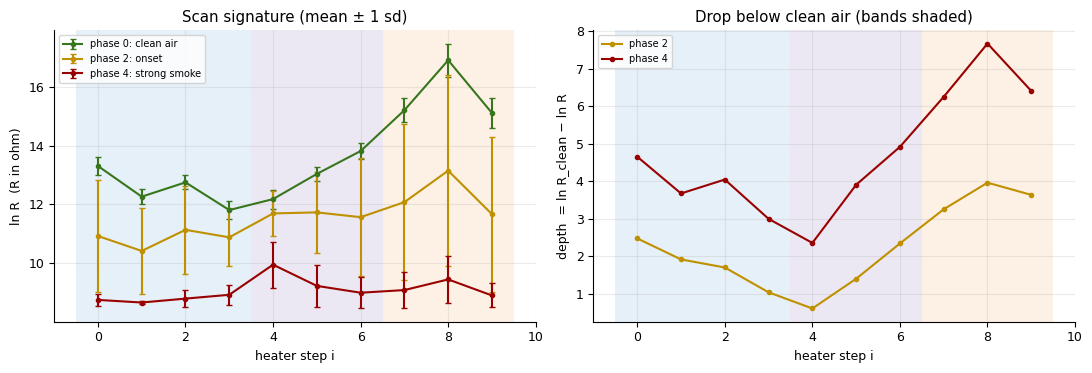

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
steps = np.arange(10)
for p, c, lab in ((0, "#38761d", "phase 0: clean air"), (2, "#bf9000", "phase 2: onset"), (4, "#990000", "phase 4: strong smoke")):
    m = R["phase"] == p
    mu, sd = R["lnR"][m].mean(0), R["lnR"][m].std(0)
    ax[0].errorbar(steps, mu, yerr=sd, color=c, marker="o", ms=3, capsize=2, label=lab)
base0 = np.median(R["lnR"][R["phase"] == 0], axis=0)
for p, c in ((2, "#bf9000"), (4, "#990000")):
    ax[1].plot(steps, base0 - R["lnR"][R["phase"] == p].mean(0), color=c, marker="o", ms=3, label=f"phase {p}")
for a in ax:
    for (lo, hi), col in zip(CFG.bands, ("#cfe2f3", "#d9d2e9", "#fce5cd")):
        a.axvspan(lo - 0.5, hi - 0.5, color=col, alpha=0.5, lw=0)
ax[0].set(xlabel="heater step i", ylabel="ln R  (R in ohm)", title="Scan signature (mean ± 1 sd)")
ax[1].set(xlabel="heater step i", ylabel="depth  = ln R_clean − ln R", title="Drop below clean air (bands shaded)")
ax[0].legend(fontsize=7); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
print("Depth per band in strong smoke (phase 4):", np.round([(base0 - R['lnR'][R['phase'] == 4].mean(0))[a:b].mean() for a, b in CFG.bands], 2))

**Reading.** In clean air the ten points are stable; in smoke they all move down, by different amounts per step. The response here is large (a depth of 3.7 to 6.8 in the bands, i.e. a resistance divided by a factor of about 40 to 900), which makes strong smoke easy. The hard cases are weak and distant sources, treated in stage 6.

## 1. Stage 1 — Quality check

**Purpose.** A wrong reading must never be mistaken for smoke, and must never contaminate the filter or the baseline.

A scan is **out of range** if
$$
\exists i:\ R_i\notin[R_{\min},R_{\max}]\ \ \text{or}\ \ T\notin[T_{\min},T_{\max}]\ \ \text{or}\ \ \mathrm{RH}\notin[0,100],
$$
with $[R_{\min},R_{\max}]=[1\,\mathrm{k\Omega},\,120\,\mathrm{M\Omega}]$ and $[T_{\min},T_{\max}]=[-40,\,85]\,^\circ$C.

- An out-of-range scan is **ignored** (it enters no state). Only $n_{\text{bad}}=3$ in a row raise the *sensor fault* class.
- A sensor repeating **exactly** the same scan $n_{\text{stuck}}=12$ times in a row is *stuck*: fault at once.
- A **spike flag** is raised if $\max_i|x_i-\tilde x_i|>\delta_{\text{spike}}=1.5$, with $\tilde x$ the median of the scans seen so far. It is informational: the scan is kept.

In [3]:
scan = d["gas"][R["idx"][5]]; T = d["temp"][R["idx"][5]]; H = d["rh"][R["idx"][5]]
def q(label, gas=scan, temp=T, rh=H):
    f, _ = stages.quality_flags(gas, temp, rh, None, 0, CFG)
    print(f"{label:<44s} out of range: {'yes' if f & F_RANGE else 'no '}")
q("a real clean scan")
q("one step at 500 ohm (below 1 kohm)", np.r_[500.0, scan[1:]])
q("one step at 130 Mohm (above 120 Mohm)", np.r_[1.3e8, scan[1:]])
q("saturated sensor, 102.4 Mohm on all steps", np.full(10, 102.4e6))
q("temperature 90 degC", temp=np.full(10, 90.0))
q("humidity 101 %", rh=np.full(10, 101.0))

same, flagged_at = 0, None
for k in range(1, 16):                       # the same scan again and again
    f, same = stages.quality_flags(scan, T, H, scan, same, CFG)
    if f & F_STUCK and flagged_at is None:
        flagged_at = k
print(f"\nIdentical scan repeated: the stuck flag rises at repetition {flagged_at} (comparisons counted: {CFG.stuck_scans}).")

window = np.tile(np.log(scan), (5, 1))
print("Spike test on a filled window, step 3 moved by +1.4 ln:", stages.is_spike(np.log(scan) + np.eye(10)[3] * 1.4, window, 5, CFG.spike_ln))
print("Spike test on a filled window, step 3 moved by +1.6 ln:", stages.is_spike(np.log(scan) + np.eye(10)[3] * 1.6, window, 5, CFG.spike_ln))

a real clean scan                            out of range: no 
one step at 500 ohm (below 1 kohm)           out of range: yes
one step at 130 Mohm (above 120 Mohm)        out of range: yes
saturated sensor, 102.4 Mohm on all steps    out of range: no 
temperature 90 degC                          out of range: yes
humidity 101 %                               out of range: yes

Identical scan repeated: the stuck flag rises at repetition 12 (comparisons counted: 12).
Spike test on a filled window, step 3 moved by +1.4 ln: False
Spike test on a filled window, step 3 moved by +1.6 ln: True


**Reading.** The saturation reading of the BME688 (102.4 MΩ) is a *valid* clean-air value, so the upper bound is 120 MΩ. That bound comes from the BME688; the BME680 range must be checked in its datasheet. A reading is refused on a single bad step, but the *class* only changes after three bad scans, so a one-off glitch cannot switch the box into a fault state.

## 2. Stage 2 — Temperature and humidity compensation

**Purpose.** Remove the part of $\ln R$ explained by the air temperature and humidity, which would otherwise look like a slow drift or a false alarm.

$$
x_i=\ln R_i-a_T\,(T-25)-b_H\,(\mathrm{RH}-50)
$$

$a_T$ and $b_H$ would be fitted by least squares on clean air only, on $\ln R$, $T$ and RH **centred per run and per step**, so that only the co-movement inside a run counts.

The temperature of a scan is not the room temperature: the hot plate heats the sensor, and the reading changes with the heater setting.

Fit on the 2021 clean start (episode 0): a_T = -0.1695 ln/°C, b_H = -0.0018 ln/%RH, R² = 0.32

Same fit, run by run (clean start of each episode):
  episode 0 (2021): a_T = -0.170, b_H = -0.0018, R² = 0.32
  episode 1 (2021): a_T = -0.112, b_H = +0.0131, R² = 0.41
  episode 4 (2025): a_T = -0.170, b_H = -0.1601, R² = 0.07
  episode 5 (2025): a_T = +0.203, b_H = +0.0205, R² = 0.05

Test on episode 4 (2025 burn), clean scans after warm-up:
  no compensation (default)    false smoke   0.0 %   (70 scans)
  fitted on episode 0          false smoke   0.0 %   (70 scans)

Test on episode 5 (2025 burn), clean scans after warm-up:
  no compensation (default)    false smoke   0.0 %   (24 scans)
  fitted on episode 0          false smoke   0.0 %   (24 scans)


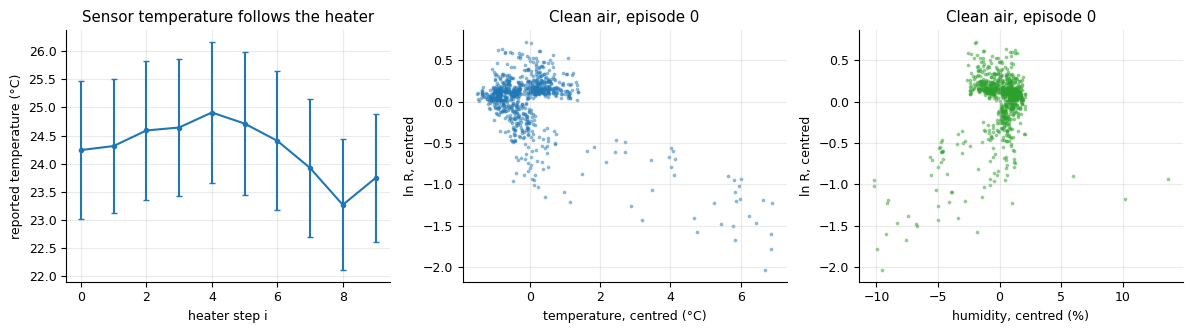

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
clean = R["phase"] == 0
ax[0].errorbar(np.arange(10), R["temp"][clean].mean(0), yerr=R["temp"][clean].std(0), marker="o", ms=3, capsize=2)
ax[0].set(xlabel="heater step i", ylabel="reported temperature (°C)", title="Sensor temperature follows the heater")
y = (R["lnR"][clean] - R["lnR"][clean].mean(0)).ravel()
t_ = (R["temp"][clean] - R["temp"][clean].mean(0)).ravel()
ax[1].scatter(t_, y, s=3, alpha=0.4)
ax[1].set(xlabel="temperature, centred (°C)", ylabel="ln R, centred", title="Clean air, episode 0")
h_ = (R["rh"][clean] - R["rh"][clean].mean(0)).ravel()
ax[2].scatter(h_, y, s=3, alpha=0.4, color="tab:green")
ax[2].set(xlabel="humidity, centred (%)", ylabel="ln R, centred", title="Clean air, episode 0")
plt.tight_layout(); plt.show()

def subset(mask):
    return {k: (v[mask] if isinstance(v, np.ndarray) and len(v) == len(mask) else v) for k, v in d.items()}

fit_mask = (d["episode"] == 0) & (d["phase"] == 0)
a_t, b_h, r2 = fit_compensation(d, fit_mask)
print(f"Fit on the 2021 clean start (episode 0): a_T = {a_t:+.4f} ln/°C, b_H = {b_h:+.4f} ln/%RH, R² = {r2:.2f}")

print("\nSame fit, run by run (clean start of each episode):")
for ep_ in (0, 1, 4, 5):
    a_, b_, r2_ = fit_compensation(d, (d["episode"] == ep_) & (d["phase"] == 0))
    print(f"  episode {ep_} ({d['experiment'][d['episode'] == ep_][0]}): a_T = {a_:+.3f}, b_H = {b_:+.4f}, R² = {r2_:.2f}")

for test_ep in (4, 5):
    sub = subset(d["episode"] == test_ep)
    rows = []
    for label, cfg in (("no compensation (default)", CFG), ("fitted on episode 0", dataclasses.replace(CFG, a_t=a_t, b_h=b_h))):
        res = replay(sub, cfg)
        clean_live = (sub["phase"] == 0) & ~res["warmup"]
        rows.append((label, float((res["cls"][clean_live] == SMOKE).mean()), int(clean_live.sum())))
    print(f"\nTest on episode {test_ep} (2025 burn), clean scans after warm-up:")
    for label, rate, n in rows:
        print(f"  {label:<28s} false smoke {rate*100:5.1f} %   ({n} scans)" if n else f"  {label:<28s} no clean scan left after the warm-up")

**Reading.** The reported temperature changes with the heater setting, so it is not an ambient measure. The coefficients fitted run by run differ widely (compare the lines above), and the explained variance is low. On the full data set, a fit on one burn gave 25.4 % false smoke on the other (research log, RES-GAS-2). The default is therefore $a_T=b_H=0$, i.e. $x_i=\ln R_i$. The two short test runs here show no false smoke with or without the fit: this small test cannot separate the two, and carries no statistical weight.

## 3. Stage 3 — Filter

**Purpose.** Remove isolated outliers without delaying a real change too much.

Per heater step, with window $w=5$:
$$
m_i^{(t)}=\operatorname{median}\big(x_i^{(t-w+1)},\dots,x_i^{(t)}\big),\qquad
e_i^{(t)}=e_i^{(t-1)}+\alpha\,\big(m_i^{(t)}-e_i^{(t-1)}\big),\quad \alpha=0.35 .
$$
The median is a non-linear filter that suppresses up to two outliers in five; the exponential smoothing is a first-order low-pass filter with a time constant of about $1/\alpha\approx 3$ scans.

Scans after the onset needed to see a drop of 1.0 ln at step 8: raw 0, median 4, filtered 6
Peak of the spike after filtering: median 0.09 ln, median + EMA 0.03 ln (raw spike: 2.50)


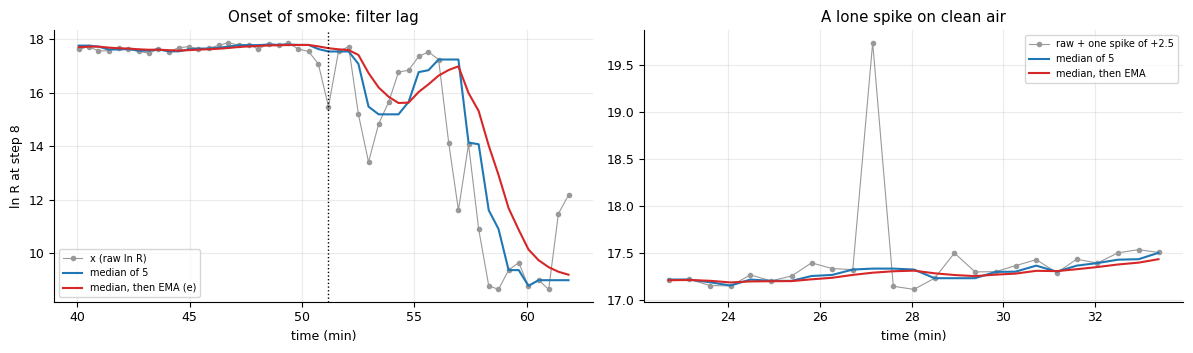

In [5]:
STEP = 8
lo, hi = max(0, onset - 25), onset + 25
x = R["lnR"][:, STEP]
med5 = np.array([np.median(x[max(0, i - 4):i + 1]) for i in range(len(x))])
ema = R["ema"][:, STEP]

# Injected lone spike on clean air, to show what the median does
xs = x.copy(); spike_at = 60; xs[spike_at] += 2.5
med_s = np.array([np.median(xs[max(0, i - 4):i + 1]) for i in range(len(xs))])
ema_s = np.empty_like(xs); ema_s[0] = med_s[0]
for i in range(1, len(xs)):
    ema_s[i] = ema_s[i - 1] + CFG.ema_alpha * (med_s[i] - ema_s[i - 1])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
t = R["t"]
ax[0].plot(t[lo:hi], x[lo:hi], ".-", color="#999", lw=0.8, label="x (raw ln R)")
ax[0].plot(t[lo:hi], med5[lo:hi], color="tab:blue", label="median of 5")
ax[0].plot(t[lo:hi], ema[lo:hi], color="tab:red", label="median, then EMA (e)")
ax[0].axvline(t[onset], color="k", ls=":", lw=1)
ax[0].set(xlabel="time (min)", ylabel=f"ln R at step {STEP}", title="Onset of smoke: filter lag")
ax[0].legend(fontsize=7)
sl = slice(spike_at - 10, spike_at + 15)
ax[1].plot(t[sl], xs[sl], ".-", color="#999", lw=0.8, label="raw + one spike of +2.5")
ax[1].plot(t[sl], med_s[sl], color="tab:blue", label="median of 5")
ax[1].plot(t[sl], ema_s[sl], color="tab:red", label="median, then EMA")
ax[1].set(xlabel="time (min)", title="A lone spike on clean air")
ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

ref = np.median(x[R["phase"] == 0])
level = 1.0
cross = lambda s: int(np.argmax((ref - s[onset:]) > level))
print(f"Scans after the onset needed to see a drop of {level} ln at step {STEP}: raw {cross(x)}, median {cross(med5)}, filtered {cross(ema)}")
print(f"Peak of the spike after filtering: median {np.max(np.abs(med_s - med5)[sl]):.2f} ln, median + EMA {np.max(np.abs(ema_s - R['ema'][:, STEP])[sl]):.2f} ln (raw spike: 2.50)")

**Reading.** The median removes the isolated spike entirely; the price is a delay on real changes, because a step change must occupy three of five samples before the median follows it. On the full data set this costs about one minute of detection delay (3.1 min against 2.0 min without the median; research log, RES-GAS-5).

## 4. Stage 4 — Baseline

**Purpose.** A reference of clean air, per heater step, against which a drop is measured. It must learn quickly, follow slow environmental drift, and **not** follow a fire.

**Learning.** The first $n_{\text{burn}}=6$ scans are ignored (the sensor settles after power-on). Once the median window is full, $n_{\text{warm}}=6$ filtered scans are averaged:
$$
b_i=\frac{1}{n_{\text{warm}}}\sum_{j=1}^{n_{\text{warm}}} e_i^{(j)} .
$$

**Following.** Only when the class is *normal*, the score is below $s_{\text{freeze}}=0.10$ and the sensor is not stuck:
$$
b_i\leftarrow b_i+\beta\,(e_i-b_i),\qquad \beta=1-e^{-\Delta t/\tau_b},\quad \tau_b=6\ \text{h}.
$$
Otherwise the baseline is **frozen**. Without this freeze, a slow fire would be absorbed as drift.

Baseline ready after 12 scans = 5.3 min at this scan rate;
at the Eco rate (300 s) the same 12 scans would take 60 min.
Baseline change over the strong smoke (step 8): 0.009 ln (signal moved by 7.01 ln)


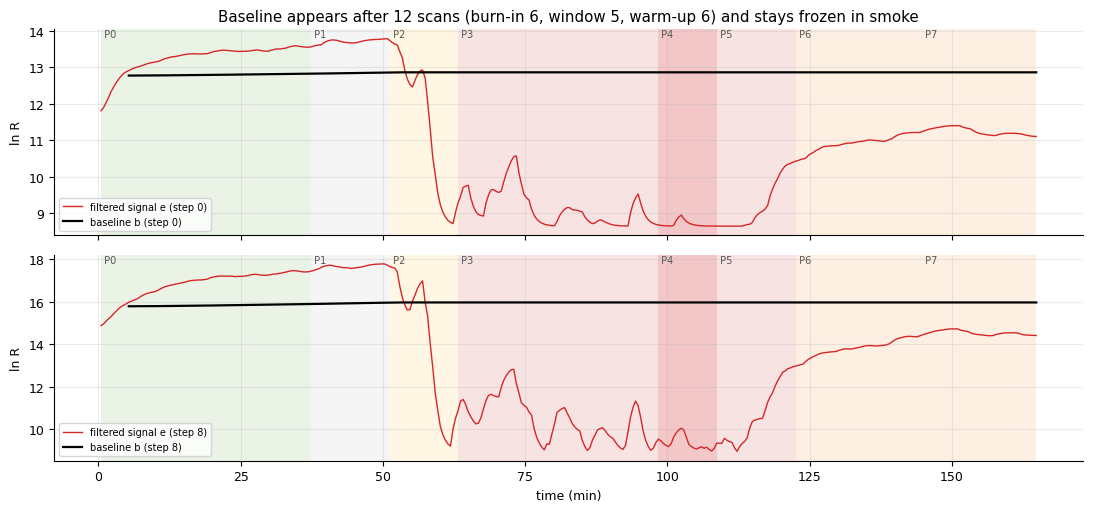

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)
for a, s in zip(ax, (0, 8)):
    a.plot(R["t"], R["ema"][:, s], color="tab:red", lw=1, label=f"filtered signal e (step {s})")
    a.plot(R["t"], R["base"][:, s], color="k", lw=1.6, label=f"baseline b (step {s})")
    a.set_ylabel("ln R")
    shade(a, R["t"], R["phase"])
    a.legend(fontsize=7, loc="lower left")
ax[1].set_xlabel("time (min)")
first_base = int(np.flatnonzero(~np.isnan(R["base"][:, 0]))[0])
ax[0].set_title(f"Baseline appears after {first_base + 1} scans (burn-in {CFG.burnin_scans}, window {CFG.median_window}, warm-up {CFG.warmup_scans}) and stays frozen in smoke")
plt.tight_layout(); plt.show()
print(f"Baseline ready after {first_base + 1} scans = {R['t'][first_base]:.1f} min at this scan rate;")
print(f"at the Eco rate (300 s) the same {first_base + 1} scans would take {(first_base + 1) * 300 / 60:.0f} min.")
frozen = (R["phase"] >= 2) & (R["phase"] <= 5)
print(f"Baseline change over the strong smoke (step 8): {np.nanmax(np.abs(R['base'][frozen, 8] - R['base'][onset - 1, 8])):.3f} ln (signal moved by {np.nanmax(np.abs(R['ema'][frozen, 8] - R['base'][onset - 1, 8])):.2f} ln)")

**Drift tolerance.** A sensor whose resistance drifts slowly (ageing, temperature, humidity) must not be called smoke, while a real fire must. The baseline can follow a drift of rate $\dot x$ (ln per hour) while the score stays below $s_{\text{freeze}}$; the CUSUM of stage 6 accumulates anything above its allowance $k$. A rough balance gives a tolerance of about
$$
\dot x_{\max}\approx \frac{k}{\tau_b}=\frac{0.03}{6\ \text{h}}=0.005\ \text{ln/h}.
$$
The experiment below checks this on synthetic drift with the noise level of the real clean air.

  drift 0.000 ln/h -> smoke   0.0 % of the time, peak score 0.15
  drift 0.001 ln/h -> smoke   0.0 % of the time, peak score 0.22
  drift 0.002 ln/h -> smoke   0.0 % of the time, peak score 0.17
  drift 0.003 ln/h -> smoke  14.2 % of the time, peak score 1.00
  drift 0.004 ln/h -> smoke  10.4 % of the time, peak score 1.00
  drift 0.005 ln/h -> smoke  28.3 % of the time, peak score 1.00
  drift 0.010 ln/h -> smoke  74.9 % of the time, peak score 1.00
  drift 0.020 ln/h -> smoke  87.5 % of the time, peak score 1.00
  drift 0.050 ln/h -> smoke  94.4 % of the time, peak score 1.00


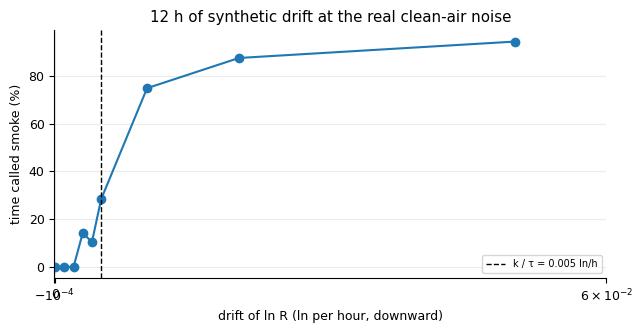

In [7]:
clean0 = d["episode"] == 0
clean0 = clean0 & (d["phase"] == 0)
ln0 = np.log(d["gas"][clean0])
sigma = np.diff(ln0, axis=0).std(axis=0) / np.sqrt(2.0)          # scan-to-scan noise per step
level = np.median(ln0, axis=0)
dt = 27.0
n = int(12 * 3600 / dt)                                          # 12 hours
rates = [0.0, 0.001, 0.002, 0.003, 0.004, 0.005, 0.01, 0.02, 0.05]
frac, peak = [], []
rng = np.random.default_rng(1)
for rate in rates:
    chain = GasChain(CFG); cls = []; sc = []
    hours = np.arange(n) * dt / 3600.0
    for k in range(n):
        x = level - rate * hours[k] + rng.normal(0, 1, 10) * sigma          # resistance drifts DOWN: the worst case
        r = chain.update(np.exp(x), np.full(10, 25.0), np.full(10, 50.0), dt)
        if not r.warmup:
            cls.append(r.cls == SMOKE); sc.append(r.score)
    frac.append(100 * np.mean(cls)); peak.append(max(sc))
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(rates, frac, "o-")
ax.axvline(CFG.cusum_k / (CFG.tau_base_s / 3600), color="k", ls="--", lw=1, label="k / τ = 0.005 ln/h")
ax.set(xscale="symlog", xlim=(-1e-4, 0.06), xlabel="drift of ln R (ln per hour, downward)", ylabel="time called smoke (%)",
       title="12 h of synthetic drift at the real clean-air noise")
ax.legend(fontsize=7); plt.tight_layout(); plt.show()
for r_, f_, p_ in zip(rates, frac, peak):
    print(f"  drift {r_:5.3f} ln/h -> smoke {f_:5.1f} % of the time, peak score {p_:.2f}")

**Reading.** A slow drift is absorbed and raises no alarm; above a threshold rate the baseline cannot keep up and the drift is classified as smoke. Each rate is a single random realisation, so the percentages are noisy. The estimate $k/\tau_b=0.005$ ln/h is an upper bound: the measured threshold lies at or slightly below it (see the table above). This is a **design limit**, not a bug: a fire and a fast drift look the same to a single sensor. Detecting a fast drift as a fault would need a second source of information, which the gateway provides (fusion with the other sensors).

## 5. Stage 5 — Depth per band

**Purpose.** Measure how far the signal fell below clean air, and where.

$$
d_i=b_i-e_i,\qquad D_k=\frac{1}{|\mathcal{B}_k|}\sum_{i\in\mathcal{B}_k}d_i,\qquad D_{\max}=\max\!\big(0,\max_k D_k\big).
$$

A positive $d_i$ means the resistance fell. Averaging within a band reduces noise; taking the maximum over the bands keeps the detection sensitive to a response confined to one range of heater temperatures. The step $i^\star=\arg\max_i d_i$ is also reported.

Step of the maximum drop in strong smoke: 8


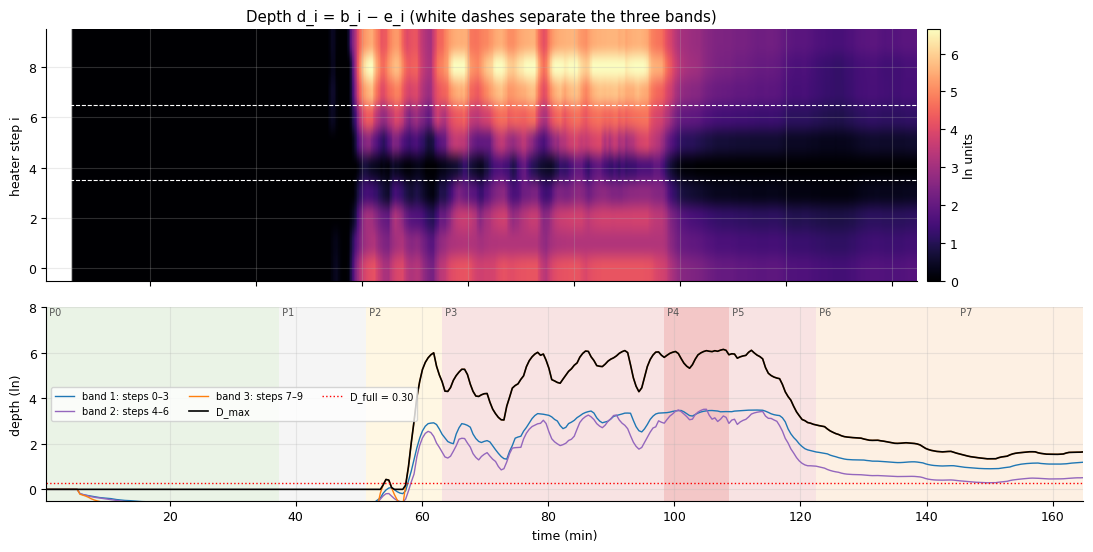

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
depth = R["base"] - R["ema"]
im = ax[0].imshow(depth.T, aspect="auto", origin="lower", extent=[R["t"][0], R["t"][-1], -0.5, 9.5],
                  cmap="magma", vmin=0, vmax=np.nanpercentile(depth, 99))
for edge in (3.5, 6.5):
    ax[0].axhline(edge, color="w", lw=0.8, ls="--")
ax[0].set(ylabel="heater step i", title="Depth d_i = b_i − e_i (white dashes separate the three bands)")
plt.colorbar(im, ax=ax[0], pad=0.01, label="ln units")
for k, c in enumerate(("tab:blue", "tab:purple", "tab:orange")):
    ax[1].plot(R["t"], R["bands"][:, k], color=c, lw=1, label=f"band {k + 1}: steps {CFG.bands[k][0]}–{CFG.bands[k][1] - 1}")
ax[1].plot(R["t"], R["depth"], "k", lw=1.2, label="D_max")
ax[1].axhline(CFG.depth_full, color="r", ls=":", lw=1, label="D_full = 0.30")
ax[1].set(xlabel="time (min)", ylabel="depth (ln)", ylim=(-0.5, 8)); ax[1].legend(fontsize=7, ncol=3)
shade(ax[1], R["t"], R["phase"])
plt.tight_layout(); plt.show()
print("Step of the maximum drop in strong smoke:", np.bincount(R["peak"][(R["phase"] >= 3) & (R["phase"] <= 5)]).argmax())

**Reading.** Before the baseline exists no depth is computed (blank at the start). In clean air the depth fluctuates around zero; in smoke the drop is large on every step, strongest on the high-temperature steps in this recording. The pattern across steps is the information a single resistance cannot give.

## 6. Stage 6 — Score

**Purpose.** One number in $[0,1]$ that reacts fast to a strong drop and also to a weak drop that persists.

**Instant score:**
$$
s_{\text{inst}}=\operatorname{clip}\!\left(\frac{D_{\max}}{D_{\text{full}}},0,1\right),\qquad D_{\text{full}}=0.30 .
$$

**CUSUM** (cumulative sum, Page 1954): accumulate the excess of the depth over an allowance $k$, and halve the sum when quiet:
$$
C_t=\begin{cases}C_{t-1}+(D_{\max}-k)& D_{\max}>k\\[2pt] \tfrac12\,C_{t-1}&\text{otherwise}\end{cases},\qquad C_t\le 1.5\,h,\quad k=0.03,\ h=1.
$$

**Final score:**
$$
s=\max\!\Big(s_{\text{inst}},\ \min\big(C_t/h,\,1\big)\Big).
$$

A weak response may never reach $s_{\text{inst}}\ge0.40$, but a persistent one makes $C_t$ grow. To see this, the recorded response is scaled down with `dilute` (the part of $\ln R$ added by the fire is multiplied by a factor, and the sensor noise is kept). This is a **proxy for distance, not a physical model**.

factor 1.00: first smoke at scan 121 (onset at 114), score max 1.00, instant max 1.00, CUSUM max 1.00
factor 0.04: first smoke at scan 132 (onset at 114), score max 1.00, instant max 0.92, CUSUM max 1.00
factor 0.01: first smoke at scan 142 (onset at 114), score max 1.00, instant max 0.36, CUSUM max 1.00


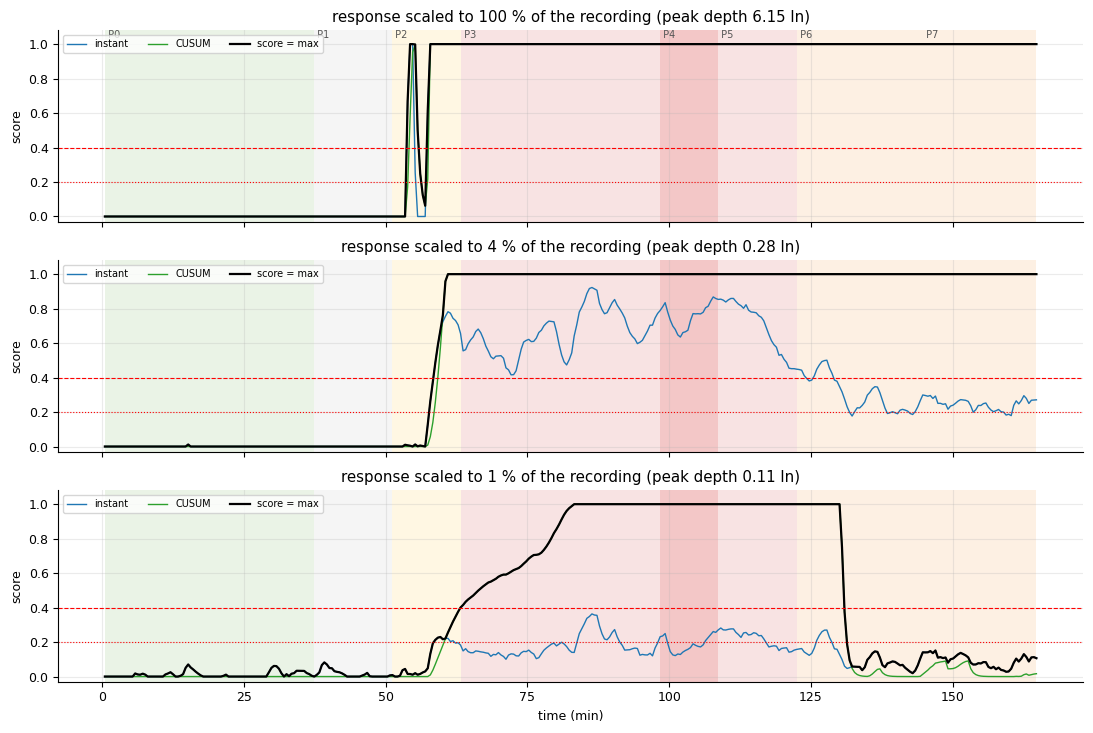

In [9]:
factors = (1.0, 0.04, 0.01)
fig, ax = plt.subplots(len(factors), 1, figsize=(11, 7.4), sharex=True)
for a, f in zip(ax, factors):
    dd = dilute(d, f, seed=3)
    Rf = run_episode(EP, data=dd)
    inst = np.array([stages.instant_score(x, CFG.depth_full) for x in Rf["depth"]])
    cum = np.minimum(Rf["cusum"] / CFG.cusum_h, 1.0)
    a.plot(Rf["t"], inst, color="tab:blue", lw=1, label="instant")
    a.plot(Rf["t"], cum, color="tab:green", lw=1, label="CUSUM")
    a.plot(Rf["t"], Rf["score"], "k", lw=1.6, label="score = max")
    a.axhline(CFG.smoke_on, color="r", ls="--", lw=0.8); a.axhline(CFG.smoke_off, color="r", ls=":", lw=0.8)
    a.set(ylabel="score", ylim=(-0.03, 1.08), title=f"response scaled to {f*100:.0f} % of the recording (peak depth {Rf['depth'].max():.2f} ln)")
    shade(a, Rf["t"], Rf["phase"], labels=(f == factors[0]))
    a.legend(fontsize=7, loc="upper left", ncol=3)
    first = np.flatnonzero(Rf["cls"] == SMOKE)
    print(f"factor {f:4.2f}: first smoke at scan {first[0] if len(first) else None}"
          f" (onset at {onset}), score max {Rf['score'].max():.2f}, instant max {inst.max():.2f}, CUSUM max {cum.max():.2f}")
ax[-1].set_xlabel("time (min)")
plt.tight_layout(); plt.show()

**Reading.** At 1 % the peak depth is about 0.11 ln: the instant score stays below the 0.40 threshold (printed maximum 0.36) and only the CUSUM brings the class to smoke, 28 scans after the onset instead of 7. At about 0.8 % and below, even the CUSUM no longer sustains the call for long (in a test run, recall fell from 0.99 to 0.38). While the diluted depth stays above $D_{\text{full}}=0.30$ the instant score saturates. Once the response is weaker than that, the instant score stays low and only the CUSUM, which accumulates the persistent excess over $k$, carries the score over the threshold, later. This is the purpose of having both terms. The price is a longer delay and a higher exposure to slow disturbances (stage 4).

## 7. Stage 7 — Class

**Purpose.** Turn the score into a decision that does not flicker.

**Wanted class** (before debounce), with $c$ the current class:
$$
\text{want}=\begin{cases}
\text{smoke}& s\ge s_{\text{on}}=0.40\\
c& s_{\text{off}}=0.20\le s<s_{\text{on}}\ \text{and}\ c=\text{smoke}\quad\text{(hysteresis)}\\
\text{normal}&\text{otherwise}
\end{cases}$$
A stuck sensor wants *sensor fault*. The *decoy* class is switched off: there is no real decoy data yet.

**Debounce.** A new class must be wanted for $n$ scans in a row: $n=1$ for a fault, $n_{\text{on}}=2$ to enter smoke, $n_{\text{off}}=3$ to return to normal. A different wanted class restarts the count.

wanted : normal  SMOKE normal  SMOKE  SMOKE  SMOKE normal normal  SMOKE normal normal normal  FAULT
class  : normal normal normal normal  SMOKE  SMOKE  SMOKE  SMOKE  SMOKE  SMOKE  SMOKE normal  FAULT
Phase 2 starts at minute 51.2; first scan classified as smoke: minute 54.3 -> delay 3.1 min (7 scans).
Class returns to normal at minute: never in this recording


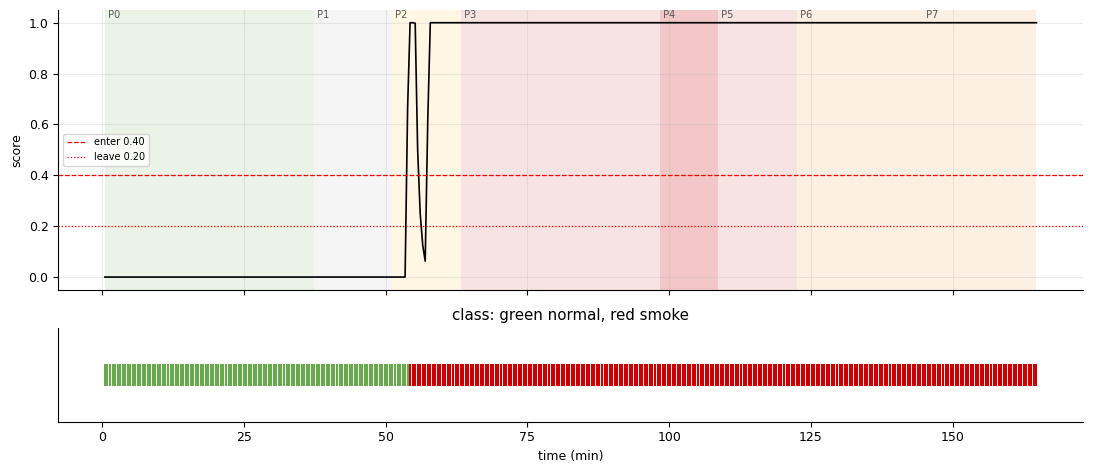

In [10]:
# 1) The debounce rule alone, on a hand-made sequence of "wanted" classes
seq = [NORMAL, SMOKE, NORMAL, SMOKE, SMOKE, SMOKE, NORMAL, NORMAL, SMOKE, NORMAL, NORMAL, NORMAL, FAULT]
cls, cand, n, out = NORMAL, NORMAL, 0, []
for w in seq:
    cls, cand, n = stages.debounce(cls, cand, n, w, CFG)
    out.append(cls)
names = {NORMAL: "normal", SMOKE: "SMOKE", FAULT: "FAULT"}
print("wanted :", " ".join(f"{names[w]:>6s}" for w in seq))
print("class  :", " ".join(f"{names[c]:>6s}" for c in out))

# 2) The whole class decision on the real episode
fig, ax = plt.subplots(2, 1, figsize=(11, 4.8), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax[0].plot(R["t"], R["score"], "k", lw=1.2)
ax[0].axhline(CFG.smoke_on, color="r", ls="--", lw=0.9, label="enter 0.40")
ax[0].axhline(CFG.smoke_off, color="r", ls=":", lw=0.9, label="leave 0.20")
ax[0].set(ylabel="score"); ax[0].legend(fontsize=7, loc="center left"); shade(ax[0], R["t"], R["phase"])
colors = np.array(["#6aa84f", "#cc0000", "#e69138", "#674ea7"])
ax[1].scatter(R["t"], np.zeros_like(R["t"]), c=colors[R["cls"]], marker="|", s=250)
ax[1].set(yticks=[], xlabel="time (min)", title="class: green normal, red smoke"); ax[1].grid(False)
plt.tight_layout(); plt.show()

first = int(np.flatnonzero(R["cls"] == SMOKE)[0])
print(f"Phase 2 starts at minute {R['t'][onset]:.1f}; first scan classified as smoke: minute {R['t'][first]:.1f}"
      f" -> delay {R['t'][first] - R['t'][onset]:.1f} min ({first - onset} scans).")
back = np.flatnonzero((R["cls"] == NORMAL) & (np.arange(len(R["cls"])) > first))
print("Class returns to normal at minute:", f"{R['t'][back[0]]:.1f}" if len(back) else "never in this recording")

**Reading.** The two thresholds create a dead band: the class enters smoke at 0.40 but only leaves below 0.20, which avoids chattering when the score hovers near a threshold. The debounce adds a delay of one scan to enter smoke and two to leave. Together with the median filter, this accounts for the few minutes measured between the onset of the burn and the first alert. In this recording the class never returns to normal: the burn ends while the resistance is still far below clean air (phases 6 and 7 keep a depth of about 2 to 3 ln), and the baseline is frozen, as intended.

## 8. End to end on the sample

The same chain, with default settings, replayed on the six episodes of the sample (a fresh chain per episode). Clean air is phase 0 after the warm-up; strong smoke is phases 3 to 5; the delay is counted from the start of phase 2.

In [11]:
res = replay(d)
print(f"{'burn':<6s}{'episodes':>9s}{'false smoke':>14s}{'recall':>9s}{'fault':>8s}{'median delay':>14s}")
for burn in ("2021", "2025"):
    m = metrics(d, res, burn, start_phase=2)
    n_ep = len(np.unique(d["episode"][d["experiment"] == burn]))
    print(f"{burn:<6s}{n_ep:>9d}{m['false_smoke_clean']*100:>13.1f}%{m['recall_strong']:>9.3f}{m['fault_in_strong']*100:>7.1f}%{m['delay_min_median']:>11.1f} min")
print("\nPer episode (node, scan period, false smoke on clean air, delay):")
for ep in np.unique(d["episode"]):
    sub = subset(d["episode"] == ep)
    r_ = replay(sub); m = metrics(sub, r_, start_phase=2)
    fs = "n/a (no clean scan after the warm-up)" if m["clean_scans"] == 0 else f"{m['false_smoke_clean']*100:5.1f} % of {m['clean_scans']} clean scans"
    note = "  <- alarm before the onset: a false alarm, not a fast detection" if m["delay_min_median"] < 0 else ""
    print(f"  ep {ep}: node {sub['node'][0]}, period {np.median(sub['dt']):4.0f} s, false smoke {fs}, delay {m['delay_min_median']:.1f} min{note}")

burn   episodes   false smoke   recall   fault  median delay
2021          2          0.0%    1.000    0.0%        2.9 min
2025          4          9.2%    1.000    0.0%        2.6 min

Per episode (node, scan period, false smoke on clean air, delay):
  ep 0: node 1, period   27 s, false smoke   0.0 % of 71 clean scans, delay 3.1 min
  ep 1: node 1, period   27 s, false smoke   0.0 % of 71 clean scans, delay 2.7 min
  ep 2: node 2, period   25 s, false smoke n/a (no clean scan after the warm-up), delay 1.6 min
  ep 3: node 3, period   77 s, false smoke  66.7 % of 15 clean scans, delay -14.2 min  <- alarm before the onset: a false alarm, not a fast detection
  ep 4: node 4, period   27 s, false smoke   0.0 % of 70 clean scans, delay 3.6 min
  ep 5: node 5, period   37 s, false smoke   0.0 % of 24 clean scans, delay 7.9 min


**Reading.** On this small sample the strong smoke is always found, with no fault, and the delay is a few minutes at the recorded scan rate. The only false smoke comes from the episode recorded with a slow scan (about 77 s between scans, few clean scans), which is the known weak point recorded in the research log (RES-GAS-1). Its negative delay means the alarm came before the burn started, so the 2025 median delay above is pulled down by that false alarm. The episode with 11 clean scans leaves none after the warm-up, so it contributes nothing to the false-smoke rate. On the **full** data set (38 episodes, 13 097 scans) the rates are 0.0 % and 1.9 % false smoke, recall 1.000 and no fault on both burns.

## 9. What this does and does not show

**Shown.** Each stage has a clear role, a closed-form rule and a measurable effect; the chain finds strong and diluted smoke on real recordings of a sibling sensor, and rejects isolated spikes and slow drift within stated limits.

**Not shown.**
- Anything about the **BME680** itself: its resistance range, its response to smoke, its heater profile and the consumption of a scan are unknown. The scale ($D_{\text{full}}$), the thresholds and the CUSUM were set on BME688/690 data.
- The pace of the box: counts are in scans, recordings come at about 27 s, while the Eco mode scans every 300 s. The delay and the one-hour baseline learning at that pace are not measured.
- Other fuels, distances, decoys (steam, cooking, dust) and wind. Dilution is a stand-in for distance.
- Generalisation: two burns of one experiment series, six episodes in this sample.

**Next steps.** Record clean air and several smoke sources with the BME680; replay the real data at the Eco pace; define the 10-step heater profile; port the stages to C and check them against these functions.

## References
- Page, E. S. (1954). Continuous inspection schemes. *Biometrika*, 41(1/2), 100–115.
- Bosch Sensortec. BME680 / BME688 datasheets (heater control, forced mode, gas resistance).
- Anedda, M. et al. *Dataset Smoke Detection*. Mendeley Data, DOI 10.17632/48j7mm8k56.1 (CC BY 4.0).
- Project research log: `docs/research/box-gas-chain.md` (RES-GAS-1 to 7); equations: `docs/technical-reference.md`, section 2.